# fibonacci_collision_analysis

有限1次元Fibonacci-QECCで、任意消失と連続消失の性能差を巡回orbitのdifference supportから調べます。
既存の `fibonacci_seed_variation`、`fibonacci_recoverability_kl`、`fibonacci_finite_size_scaling`、
`fibonacci_logical_information_leakage` の保存済みコードと定義を照合しました。出典・SHA256は `reference/` にあります。

本番設定のNotebookと、小規模実行済みの `_example.ipynb` を同梱します。本番設定ではまずvalidation・計算量計画・benchmarkを表示します。
手動セルの `RUN_FULL_ANALYSIS=True` で本計算を行います。小規模例は仮説の一般的な証明ではありません。

## 1. 研究目的と検証する問い

- Q1: $d_{\rm cross}$ と任意消失訂正率に関連があるか。
- Q2: $\ell_{\rm cross,min}$ と連続消失訂正率に関連があるか。
- Q3–Q4: 任意消失に弱く連続消失に強いpairに、小weight・大spanのsupportが多いか。
- Q5: spectrum・multiplicity・期待collision数は訂正率予測の指標となるか。
- Q6: その指標を新しいseed pairの設計に使えるか。

「collisionが訂正失敗の全原因である」とは仮定しません。対角KL不一致も独立に計算します。


**実行済み小規模例**: 既存の1pair、n=0,1,2,4、m=1,2,3,4,6。exact上限200、sampledは各120draw。n=0は検証用。pair間相関は別途複数pairが必要です。

## 2–4. Collision・difference support・Hamming weight・cyclic span

siteは左から **0始まり**。$E$ は消失集合、$E^c$ は残存集合です。

$$D(x,y)=\{i:x_i\ne y_i\},\qquad x_{E^c}=y_{E^c}\iff D(x,y)\subseteq E.$$

$$w(x,y)=|D(x,y)|,\qquad \ell_{\rm cyc}(D)=\text{Dを含む最短cyclic intervalのsite数}.$$

空集合ではspan=0。非空のDを巡回順に並べ、隣接site間の距離の最大を$g_{\max}$とすると、
$\ell_{\rm cyc}=N-g_{\max}+1$です。端点も数えるので **+1** が必要です。
singletonは1、全siteならNです。N=20、D={5,6,8}なら4、D={2,10}なら9。

任意消失で固定pairをcollisionさせる最小消失数はw、連続消失ではspanです。
ただし、それらはcross collisionのしきい値であり、完全な量子符号距離を意味しません。


## 5. 手動入力セル

================================  
ここはユーザーが手動入力する  
================================

初期seedは既存解析と同じ `000111 / 010101`。Nは入力せずinflation後に計算します。
window modeでは固定window内の一様m-subsetを用います。連続消失との性能比較も同じwindowに含まれる区間で行い、
全ringのN開始位置で求める理論期待値は別列に保存します。


In [1]:
# ==========================================
# ユーザーが手動入力する解析パラメータ
# ==========================================
SEED_0 = "000111"
SEED_1 = "010101"
PAIR_ID = "L06_W03_P0001"
INFLATION_LIST = [0, 1, 2, 4]
ERASURE_DOMAIN_MODE = "full_ring"  # "full_ring" / "window"
WINDOW_SIZE_LIST = [20, 30, 50]
ERASURE_SIZE_LIST = [1, 2, 3, 4, 6]
MAX_EXACT_PATTERNS = 200
NUM_RANDOM_SAMPLES = 120
RANDOM_SEED = 42
TOP_K_DANGEROUS_SUPPORTS = 20
SAVE_RESULTS = True
SAVE_FIGURES = True

# 追加設定もこのセルだけで変更する。
# Noneなら上の単一pair。複数pairは同じn,N,m,domain内で比較する。
LOGICAL_PAIRS = None
# 例: [{"pair_id":"p0", "seed_0":"00001111", "seed_1":"00011011"}, ...]
WINDOW_START = 0       # windowはこのsiteから右へ。ring上でwrap可能。
LOW_WEIGHT_MAX = 4
LARGE_SPAN_MIN = None  # Noneならceil(LARGE_SPAN_FRACTION*N)
LARGE_SPAN_FRACTION = 0.5
HIGH_RATE_THRESHOLD = 0.8
LOW_RATE_THRESHOLD = 0.2
STORE_PAIR_DETAILS = True  # True: 全cross/self組のshiftとDをcsv.gzに保存
INCLUDE_ALL_SUPPORT_POSITIONS = False  # 全supportはhex maskで保存。危険supportは常に位置も保存。
SAVE_COLLISION_PROFILES = False  # True: 各残存patternのn0(r), n1(r)
COMPUTE_LEAKAGE = True  # True: I_RE, D_Z, D_Xも計算（追加コスト）
MAX_LEAKAGE_DIM = 256   # rho_REを含む最大密行列次元。超過はNA+理由。
MAX_DETAIL_ROWS = 1000000
VALIDATE_SUPPORT_PATTERNS = 3
RUN_FULL_ANALYSIS = True  # benchmark確認後にTrueで全自動計算
OUTPUT_DIR = "example_results"


================================  
ここから下は基本的に自動計算  
================================

In [2]:
from pathlib import Path
import json, sys, unittest
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from collision_core import *
from collision_analysis import run_analysis, experiment_plan, compare_reference_rates, save_results
from collision_reporting import make_figures, conclusions
pd.set_option("display.max_columns", 24)
CONFIG = {k:v for k,v in list(globals().items()) if k.isupper() and not k.startswith("_") and k != "CONFIG"}
print("inflation: 0→1, 1→10 / site 0: leftmost / self pair: unordered i<j")


inflation: 0→1, 1→10 / site 0: leftmost / self pair: unordered i<j


## 6. Seed条件・実装のvalidation

同じk0/k1、巡回非同値、環の境界を含む1回の隣接01/10交換で相手の巡回同値類に移らないことを自動確認します。
inflation後もorbitの非交差を確認します。原論文の追加的なself-swap条件は、既存のpair間条件とは分けて診断します。

小さい系で文字列の残存pattern判定とbit-mask判定、明示的なpartial traceとKLを照合します。
周期的なorbitの重複除去、M0≠M1、空/全消失、window、期待値と実測平均も検証します。


In [3]:
selected = LOGICAL_PAIRS or [dict(pair_id=PAIR_ID, seed_0=SEED_0, seed_1=SEED_1)]
display(pd.DataFrame([dict(p, **validate_pair(p["seed_0"], p["seed_1"])) for p in selected]))
suite = unittest.defaultTestLoader.loadTestsFromNames(["test_collision_core", "test_collision_kl", "test_collision_analysis"])
test_result = unittest.TextTestRunner(verbosity=1).run(suite)
assert test_result.wasSuccessful(), "validation failed"
print("validation tests:", test_result.testsRun)
assert difference_support("010010", "011000") == {2,4}
assert cyclic_span({5,6,8},20) == 4
assert cyclic_span({2,10},20) == 9


validation tests: 15


...............
----------------------------------------------------------------------
Ran 15 tests in 0.187s

OK


,pair_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1
0,L06_W03_P0001,000111,010101,6,3,3,True,True,True


## 7–8. Inflation・N・cyclic orbit・計算前benchmark

inflation回数nは0以上。n=0は幾何と実装の検証用であり、原論文のinflation後の保証を適用しません。
orbitは最初に現れた左cyclic shift順で重複を除き、実際のshift indexを保存します。
Python intのXORとbit_countを用い、全消失patternごとのpair XORは行いません。

benchmarkはgeometryの見積りです。KL全pattern計算・漏洩の固有値計算・CSV出力は別のコストがあります。
大規模実験ではcompactなunique support表を標準とし、全pairのDリストはオプションで保存します。


In [4]:
size_rows=[]; benchmark_rows=[]
for p in selected:
    for n in INFLATION_LIST:
        a,b=inflate(p["seed_0"],n),inflate(p["seed_1"],n)
        size_rows.append(dict(pair_id=p["pair_id"],inflation_n=n,N=len(a),orbit_size_0=len(cyclic_orbit(a)),orbit_size_1=len(cyclic_orbit(b))))
        benchmark_rows.append(dict(pair_id=p["pair_id"],**benchmark(p["seed_0"],p["seed_1"],n)))
display(pd.DataFrame(size_rows))
display(pd.DataFrame(benchmark_rows))
plan,skipped=experiment_plan(CONFIG)
display(plan)
print("planned detail rows:", int(plan.num_patterns.sum()) if len(plan) else 0)
if len(skipped): display(skipped)
if SAVE_RESULTS:
    Path(OUTPUT_DIR).mkdir(parents=True,exist_ok=True)
    pd.DataFrame(benchmark_rows).to_csv(Path(OUTPUT_DIR)/"preflight_benchmark.csv",index=False)
    plan.to_csv(Path(OUTPUT_DIR)/"preflight_plan.csv",index=False)


planned detail rows: 1740


,pair_id,inflation_n,N,orbit_size_0,orbit_size_1
0,L06_W03_P0001,0,6,6,2
1,L06_W03_P0001,1,9,9,3
2,L06_W03_P0001,2,15,15,5
3,L06_W03_P0001,4,39,39,13


,pair_id,inflation_n,N,orbit_size_0,orbit_size_1,number_cross_pairs,number_self_pairs,sampled_pairs,difference_support_seconds,estimated_total_seconds_naive,estimate_scope
0,L06_W03_P0001,0,6,6,2,12,16,12,0.000061,0.000141,naive feature computation; excludes KL/leakage...
1,L06_W03_P0001,1,9,9,3,27,39,27,0.000134,0.000328,naive feature computation; excludes KL/leakage...
2,L06_W03_P0001,2,15,15,5,75,115,75,0.000502,0.001271,naive feature computation; excludes KL/leakage...
3,L06_W03_P0001,4,39,39,13,507,819,507,0.006788,0.017754,naive feature computation; excludes KL/leakage...


,pair_id,seed_0,seed_1,inflation_n,N,domain_mode,window_size,erasure_size,erasure_type,calculation_mode,population_patterns,num_patterns,status,reason
0,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,exact,6,6,planned,
1,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,contiguous,exact,6,6,planned,
2,L06_W03_P0001,000111,010101,0,6,full_ring,6,2,arbitrary,exact,15,15,planned,
3,L06_W03_P0001,000111,010101,0,6,full_ring,6,2,contiguous,exact,6,6,planned,
4,L06_W03_P0001,000111,010101,0,6,full_ring,6,3,arbitrary,exact,20,20,planned,
5,L06_W03_P0001,000111,010101,0,6,full_ring,6,3,contiguous,exact,6,6,planned,
6,L06_W03_P0001,000111,010101,0,6,full_ring,6,4,arbitrary,exact,15,15,planned,
7,L06_W03_P0001,000111,010101,0,6,full_ring,6,4,contiguous,exact,6,6,planned,
8,L06_W03_P0001,000111,010101,0,6,full_ring,6,6,arbitrary,exact,1,1,planned,
9,L06_W03_P0001,000111,010101,0,6,full_ring,6,6,contiguous,exact,6,6,planned,


## 9–10. Cross / self pairとdifference support

$$|a_L\rangle=|O_a|^{-1/2}\sum_{x\in O_a}|x\rangle.$$

crossは$O_0\times O_1$の全組。selfは各orbit内の$i<j$のみです。
`support_multiplicity(D)` は同じ絶対site集合を与える組数であり、回転した別のDは別supportです。
同時巡回移動はwとspanを変えないので、feature計算だけに対称性を使います。
全pairの数え方やsupportの絶対位置は変えません。
全supportはhex maskとして保存し、`mask_to_sites(int(mask,16),N)`で絶対位置に戻せます。
危険なsupportには位置リストも保存します。`INCLUDE_ALL_SUPPORT_POSITIONS=True`で全supportの位置も保存します。

`STORE_PAIR_DETAILS=True` の場合、shift・w・span・difference_positions・multiplicityを全組について出力します。
Falseの場合も全組を含む正確なspectrum、unique support表、重要なshift pairを保持します。


In [5]:
RESULTS = None
if RUN_FULL_ANALYSIS:
    RESULTS = run_analysis(CONFIG)
    display(RESULTS["summary"])
else:
    print("準備完了。本計算は手動セルのRUN_FULL_ANALYSIS=Trueで実行。実行済み例は_example.ipynb。")


L06_W03_P0001: inflation n=0, geometry
  N=6, W=6, m=1: arbitrary / contiguous
  N=6, W=6, m=2: arbitrary / contiguous
  N=6, W=6, m=3: arbitrary / contiguous
  N=6, W=6, m=4: arbitrary / contiguous
  N=6, W=6, m=6: arbitrary / contiguous
L06_W03_P0001: inflation n=1, geometry
  N=9, W=9, m=1: arbitrary / contiguous
  N=9, W=9, m=2: arbitrary / contiguous
  N=9, W=9, m=3: arbitrary / contiguous
  N=9, W=9, m=4: arbitrary / contiguous
  N=9, W=9, m=6: arbitrary / contiguous
L06_W03_P0001: inflation n=2, geometry
  N=15, W=15, m=1: arbitrary / contiguous
  N=15, W=15, m=2: arbitrary / contiguous
  N=15, W=15, m=3: arbitrary / contiguous
  N=15, W=15, m=4: arbitrary / contiguous
  N=15, W=15, m=6: arbitrary / contiguous
L06_W03_P0001: inflation n=4, geometry
  N=39, W=39, m=1: arbitrary / contiguous
  N=39, W=39, m=2: arbitrary / contiguous
  N=39, W=39, m=3: arbitrary / contiguous
  N=39, W=39, m=4: arbitrary / contiguous
  N=39, W=39, m=6: arbitrary / contiguous


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,...,number_cross_pairs,number_unique_cross_supports,low_weight_max,large_span_min,low_weight_large_span_pair_fraction,low_weight_large_span_unique_fraction,low_weight_pair_fraction,d_self_0,ell_self_0_min,d_self_1,ell_self_1_min,geometry_seconds
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,12,6,4,3,1.000000,1.000000,1.000000,2,4,6,6,0.000084
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,27,27,4,5,1.000000,1.000000,1.000000,2,4,6,8,0.000213
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,...,75,75,4,8,0.200000,0.200000,0.200000,6,6,6,12,0.000320
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,...,507,507,4,20,0.076923,0.076923,0.076923,6,12,6,28,0.002442


## 11–14. Hamming spectrum・span spectrum・joint分布・危険なsupport

`spectra` はpair数で数えたA(w)、B(ell)とunique support数を区別します。
`joint_spectrum` は(w,ell)の同時分布。`dangerous_supports` は小weight、高multiplicityの順に抽出します。
small-weight / large-spanは手動セルの閾値を使用し、pairで重み付けした割合とunique supportの割合を分けます。
小距離が1組だけなのか、多数の組に由来するのかを区別して読んでください。


In [6]:
if RESULTS is not None:
    display(RESULTS["spectra"])
    display(RESULTS["joint_spectrum"].head(30))
    display(RESULTS["dangerous_supports"])
    display(RESULTS["low_weight_large_span_supports"].head(50))


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,metric_type,value,count,fraction,cumulative_count,cumulative_fraction
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming,2,6,0.500000,6,0.500000
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming,4,6,0.500000,12,1.000000
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming_unique,2,3,0.500000,3,0.500000
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming_unique,4,3,0.500000,6,1.000000
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_span,4,6,0.500000,6,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,self_1_span,38,26,0.333333,78,1.000000
160,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,self_1_span_unique,28,13,0.166667,13,0.166667
161,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,self_1_span_unique,33,13,0.166667,26,0.333333
162,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,self_1_span_unique,36,26,0.333333,52,0.666667


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,pair_type,hamming_weight,cyclic_span,count,fraction,unique_count
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,2,4,6,0.500000,3
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,4,5,6,0.500000,3
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,self_0,2,4,6,0.400000,3
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,self_0,4,5,6,0.400000,3
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,self_0,6,6,3,0.200000,1
5,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,self_1,6,6,1,1.000000,1
6,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,4,5,18,0.666667,18
7,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,4,6,9,0.333333,9
8,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,self_0,2,4,9,0.250000,9
9,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,self_0,4,6,9,0.250000,9


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,pair_type,support_mask,difference_positions,hamming_weight,cyclic_span,multiplicity,support_multiplicity,shift_index_a,shift_index_b
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x12,"[1, 4]",2,4,2,2,0,0
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x24,"[0, 3]",2,4,2,2,1,1
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x9,"[2, 5]",2,4,2,2,2,0
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x2d,"[0, 2, 3, 5]",4,5,2,2,0,1
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x1b,"[1, 2, 4, 5]",4,5,2,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x180000c00,"[6, 7, 27, 28]",4,20,1,1,15,10
62,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x300001800,"[5, 6, 26, 27]",4,20,1,1,16,11
63,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x600003000,"[4, 5, 25, 26]",4,20,1,1,17,12
64,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0xc00006000,"[3, 4, 24, 25]",4,20,1,1,18,0


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,pair_type,support_mask,difference_positions,hamming_weight,cyclic_span,multiplicity,support_multiplicity,shift_index_a,shift_index_b
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x12,"[1, 4]",2,4,2,2,0,0
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x2d,"[0, 2, 3, 5]",4,5,2,2,0,1
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x1b,"[1, 2, 4, 5]",4,5,2,2,1,0
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x24,"[0, 3]",2,4,2,2,1,1
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x9,"[2, 5]",2,4,2,2,2,0
5,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x36,"[0, 1, 3, 4]",4,5,2,2,2,1
6,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,0x5c,"[2, 4, 5, 6]",4,5,1,1,0,0
7,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,0x87,"[1, 6, 7, 8]",4,5,1,1,0,1
8,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,0x131,"[0, 3, 4, 8]",4,6,1,1,0,2
9,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross,0x63,"[2, 3, 7, 8]",4,6,1,1,1,0


## 15–16. Collision probabilityと期待collision数

全ringの一様m-erasureでは、固定Dのweightがwのとき
$$P(D\subseteq E)=\frac{\binom{N-w}{m-w}}{\binom Nm}\quad(w\le m),$$
それ以外は0。window Wでは$D\subseteq W$を満たすものだけに$N\to |W|$を適用します。

$$\mathbb E[C_{\rm cross}|m]=\sum_D\operatorname{multiplicity}(D)P(D\subseteq E).$$

これは線形性から**組数の期待値として正確**です。$P(C>0)$とは異なり1を超え得ます。
unique support同士でもeventが重なるので、その確率を単純に足しても発生確率にはなりません。
発生確率は全探索または実際の一様抽出で別途集計します。

全ringの連続消失の期待値はN個の開始位置に関する正確な値です。
`expected_cross_collision_contiguous_full_ring` に保存し、window比較にはwindowに含まれる区間の期待値を使います。
0またはN site消失では同じ集合が複数の開始位置から生じても、開始位置を母集団とする定義を保ちます。


In [7]:
if RESULTS is not None:
    display(RESULTS["expected"])


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,...,expected_self_collision_1_arbitrary,domain_mode,window_size,expected_cross_collision_contiguous_full_ring,expected_cross_collision_contiguous,expected_self_collision_0_contiguous,expected_self_collision_1_contiguous,union_bound_arbitrary,union_bound_contiguous,number_cross_pairs,collision_probability_lower_bound_arbitrary,collision_probability_lower_bound_contiguous
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,0.000000,full_ring,6,0,0.0,0.0,0.0,0.000000,0.0,12,0.000000e+00,0.000000
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,0.000000,full_ring,6,0,0.0,0.0,0.0,0.400000,0.0,12,3.333333e-02,0.000000
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,0.000000,full_ring,6,0,0.0,0.0,0.0,1.000000,0.0,12,1.000000e-01,0.000000
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,0.000000,full_ring,6,2,2.0,2.0,0.0,1.000000,1.0,12,2.333333e-01,0.166667
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,1.000000,full_ring,6,12,12.0,15.0,1.0,1.000000,1.0,12,1.000000e+00,1.000000
5,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,0.000000,full_ring,9,0,0.0,0.0,0.0,0.000000,0.0,27,0.000000e+00,0.000000
6,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,0.000000,full_ring,9,0,0.0,0.0,0.0,0.000000,0.0,27,0.000000e+00,0.000000
7,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,0.000000,full_ring,9,0,0.0,0.0,0.0,0.000000,0.0,27,0.000000e+00,0.000000
8,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,0.000000,full_ring,9,0,0.0,1.0,0.0,0.214286,0.0,27,7.936508e-03,0.000000
9,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,0.035714,full_ring,9,5,5.0,5.0,0.0,1.000000,1.0,27,1.190476e-01,0.185185


## 17–18. 任意消失と連続消失の比較

任意消失は$\binom{|W|}{m}\le$`MAX_EXACT_PATTERNS`なら全探索。それ以外は**一様な独立復元抽出**です。
重複drawも保持し、同じN/window/mならlogical pair間で同じ消失集合を使います。
sampledの率にはWilson 95%区間、exactは実際の率を保存します。未観測collisionを「存在しない」とは判断しません。

巡回orbitの等重ね合わせは平行移動不変なので、固定mの全ring連続消失は全開始位置で同じKL判定になり、
正確な訂正率は0または1です。固定Dを含む区間の割合は中間値になり得ますが、全cross pairのcollision存在判定とは異なります。
window>Nやm>windowは`skipped`に理由を記録し、windowを黙って縮めません。


In [8]:
if RESULTS is not None:
    display(RESULTS["rates"])
    display(RESULTS["comparison"][["pair_id","inflation_n","N","window_size","erasure_size","d_cross","ell_cross_min","R_KL_arbitrary","R_KL_contiguous","P_cross_collision_arbitrary","diagonal_only_failure_rate_arbitrary","performance_type"]])


,pair_id,seed_0,seed_1,inflation_n,N,domain_mode,window_size,erasure_size,erasure_type,n_trials,n_unique_patterns,calculation_mode,...,mean_D_Z,measured_D_Z,sem_D_Z,mean_D_X,measured_D_X,sem_D_X,offdiagonal_equivalence_verified,window_start,R_KL_ci_low,R_KL_ci_high,P_cross_collision_ci_low,P_cross_collision_ci_high
0,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,6,6,exact,...,0.000000,6,0.000000,0.000000,6,0.000000,True,0,1.000000,1.000000,0.000000,0.000000
1,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,contiguous,6,6,exact,...,0.000000,6,0.000000,0.000000,6,0.000000,True,0,1.000000,1.000000,0.000000,0.000000
2,L06_W03_P0001,000111,010101,0,6,full_ring,6,2,arbitrary,15,15,exact,...,0.600000,15,0.000000,0.115470,15,0.000000,True,0,0.000000,0.000000,0.200000,0.200000
3,L06_W03_P0001,000111,010101,0,6,full_ring,6,2,contiguous,6,6,exact,...,0.666667,6,0.000000,0.000000,6,0.000000,True,0,0.000000,0.000000,0.000000,0.000000
4,L06_W03_P0001,000111,010101,0,6,full_ring,6,3,arbitrary,20,20,exact,...,0.847214,20,0.000000,0.346410,20,0.000000,True,0,0.000000,0.000000,0.600000,0.600000
5,L06_W03_P0001,000111,010101,0,6,full_ring,6,3,contiguous,6,6,exact,...,1.000000,6,0.000000,0.000000,6,0.000000,True,0,0.000000,0.000000,0.000000,0.000000
6,L06_W03_P0001,000111,010101,0,6,full_ring,6,4,arbitrary,15,15,exact,...,0.953518,15,0.000000,0.648715,15,0.000000,True,0,0.000000,0.000000,1.000000,1.000000
7,L06_W03_P0001,000111,010101,0,6,full_ring,6,4,contiguous,6,6,exact,...,1.000000,6,0.000000,0.577350,6,0.000000,True,0,0.000000,0.000000,1.000000,1.000000
8,L06_W03_P0001,000111,010101,0,6,full_ring,6,6,arbitrary,1,1,exact,...,1.000000,1,0.000000,1.000000,1,0.000000,True,0,0.000000,0.000000,1.000000,1.000000
9,L06_W03_P0001,000111,010101,0,6,full_ring,6,6,contiguous,6,1,exact,...,1.000000,6,0.000000,1.000000,6,0.000000,True,0,0.000000,0.000000,1.000000,1.000000


,pair_id,inflation_n,N,window_size,erasure_size,d_cross,ell_cross_min,R_KL_arbitrary,R_KL_contiguous,P_cross_collision_arbitrary,diagonal_only_failure_rate_arbitrary,performance_type
0,L06_W03_P0001,0,6,6,1,2,4,1.000000,1.0,0.000000,0.000000,B
1,L06_W03_P0001,0,6,6,2,2,4,0.000000,0.0,0.200000,0.800000,C
2,L06_W03_P0001,0,6,6,3,2,4,0.000000,0.0,0.600000,0.400000,C
3,L06_W03_P0001,0,6,6,4,2,4,0.000000,0.0,1.000000,0.000000,C
4,L06_W03_P0001,0,6,6,6,2,4,0.000000,0.0,1.000000,0.000000,C
5,L06_W03_P0001,1,9,9,1,4,5,1.000000,1.0,0.000000,0.000000,B
6,L06_W03_P0001,1,9,9,2,4,5,0.250000,1.0,0.000000,0.750000,intermediate
7,L06_W03_P0001,1,9,9,3,4,5,0.000000,0.0,0.000000,1.000000,C
8,L06_W03_P0001,1,9,9,4,4,5,0.000000,0.0,0.214286,0.785714,C
9,L06_W03_P0001,1,9,9,6,4,5,0.000000,0.0,0.964286,0.035714,C


## 19. KL条件・既存訂正率との照合・相関

$$\rho_E^{ab}=\operatorname{Tr}_{E^c}|a_L\rangle\langle b_L|.$$

正の等振幅なので`cross_collision == (not KL_offdiagonal)`が成立します。
一方、完全なKLには$\rho_E^{00}=\rho_E^{11}$も必要で、正規化された整数カウントを交差乗算して厳密に判定します。
M0とM1を同一と仮定しません。self collisionがゼロでも、消失部分の周辺分布の差から対角KLが失敗し得ます。
`Delta_C_self=abs(C_self_0-C_self_1)` は診断指標であり、対角条件の代用ではありません。

既存定義の`recoverable_both`は両orbit内の単射性です。量子KL成功とは別の列です。
`1-P_cross_collision`はKL訂正率の上限になりますが、対角だけで失敗する割合を差し引く必要があります。

Pearson・Spearmanは**同じn,N,m,domainで異なるlogical pairが3組以上あり、値が変動する場合のみ**計算します。
単一pairのサイズ系列をpair間相関に混ぜません。少数pairの係数は記述統計であり、汎化予測の検証ではありません。
旧率はdomain・m・Nなどが一致する行だけ比較し、新しい全探索/抽出結果に勝手に置き換えません。


In [9]:
if RESULTS is not None:
    display(RESULTS["correlations"])
    reference_comparison=compare_reference_rates(RESULTS["rates"],Path("reference"))
    display(reference_comparison)
    if SAVE_RESULTS: reference_comparison.to_csv(Path(OUTPUT_DIR)/"reference_rate_comparison.csv",index=False)


,inflation_n,N,domain_mode,window_size,erasure_size,x,y,n,pearson,spearman,status,note,Pearson,Spearman
0,0,6,full_ring,6,1,d_cross,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
1,0,6,full_ring,6,1,ell_cross_min,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
2,0,6,full_ring,6,1,expected_cross_collision_arbitrary,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
3,0,6,full_ring,6,1,expected_cross_collision_contiguous,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
4,0,6,full_ring,6,1,low_weight_large_span_unique_fraction,correction_rate_gap,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,4,39,full_ring,39,6,d_cross,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
96,4,39,full_ring,39,6,ell_cross_min,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
97,4,39,full_ring,39,6,expected_cross_collision_arbitrary,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
98,4,39,full_ring,39,6,expected_cross_collision_contiguous,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN


,seed_0,seed_1,inflation_n,N,erasure_type,erasure_size,domain_mode,window_size,R_KL_new,calculation_mode_new,n_trials,R_KL_prior,calculation_mode_prior,num_patterns,source,rate_difference,status,comparison_note
0,000111,010101,0,6,arbitrary,1,full_ring,6,1.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
1,000111,010101,0,6,contiguous,1,full_ring,6,1.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
2,000111,010101,0,6,arbitrary,2,full_ring,6,0.000000,exact,15,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
3,000111,010101,0,6,contiguous,2,full_ring,6,0.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
4,000111,010101,0,6,arbitrary,3,full_ring,6,0.000000,exact,20,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
5,000111,010101,0,6,contiguous,3,full_ring,6,0.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
6,000111,010101,0,6,arbitrary,4,full_ring,6,0.000000,exact,15,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
7,000111,010101,0,6,contiguous,4,full_ring,6,0.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
8,000111,010101,0,6,arbitrary,6,full_ring,6,0.000000,exact,1,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...
9,000111,010101,0,6,contiguous,6,full_ring,6,0.000000,exact,6,NaN,NaN,NaN,NaN,NaN,no_matching_prior_row,Exact runs should agree; sampled runs can diff...


## 20. Finite-size scalingとの接続

同じseed pairのnとNに対しd_cross、ell_cross_min、低weight比率、期待collision数を保存します。
固定mで増大するfull ringと、固定W,mのwindowは違う実験です。図表にはdomainを付け、混ぜて結論を出しません。
span/Nの閾値でlow-weight / large-spanを定める場合、Nとともに閾値も変わることを明記します。


In [10]:
if RESULTS is not None:
    display(RESULTS["summary"].sort_values(["pair_id","N"]))


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,...,number_cross_pairs,number_unique_cross_supports,low_weight_max,large_span_min,low_weight_large_span_pair_fraction,low_weight_large_span_unique_fraction,low_weight_pair_fraction,d_self_0,ell_self_0_min,d_self_1,ell_self_1_min,geometry_seconds
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,12,6,4,3,1.000000,1.000000,1.000000,2,4,6,6,0.000084
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,27,27,4,5,1.000000,1.000000,1.000000,2,4,6,8,0.000213
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,...,75,75,4,8,0.200000,0.200000,0.200000,6,6,6,12,0.000320
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,...,507,507,4,20,0.076923,0.076923,0.076923,6,12,6,28,0.002442


## 21. Information leakageとの接続

以前と同じ$D_Z=\frac12\|\rho_E^{00}-\rho_E^{11}\|_1$、$D_X=\|\rho_E^{01}\|_1$を使用します。
$I(R:E)=1+S(\rho_E)-S(\rho_{RE})$、対数は底2。
`COMPUTE_LEAKAGE=True`で計算し、行列の有効な消失basisだけを使います。
最大行列次元を超える場合、厳密KL・collision計算は保持し、漏洩値のみNAと理由を保存します。NAを0と解釈しません。

`C_cross vs D_X/I_RE`、`Delta_C_self vs D_Z`の相関は同じ設定内のpattern間の記述統計です。
profileは残存patternごとのn0(r),n1(r)ですが、それだけでは消失側の行列要素は復元できません。
KLは消失側のpattern対を含む完全なカウントで判定します。


In [11]:
if RESULTS is not None:
    display(RESULTS["leakage_correlations"])
    display(RESULTS["erasure_detail"].head(15))


,pair_id,seed_0,seed_1,inflation_n,N,domain_mode,window_size,erasure_size,erasure_type,x,y,n,pearson,spearman,status,note
0,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,C_cross,D_X,6,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
1,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,C_cross,I_RE,6,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
2,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,Delta_C_self,D_Z,6,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
3,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,arbitrary,Delta_C_self,KL_diagonal,6,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
4,L06_W03_P0001,000111,010101,0,6,full_ring,6,1,contiguous,C_cross,D_X,6,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,L06_W03_P0001,000111,010101,4,39,full_ring,39,6,arbitrary,Delta_C_self,KL_diagonal,120,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
156,L06_W03_P0001,000111,010101,4,39,full_ring,39,6,contiguous,C_cross,D_X,39,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
157,L06_W03_P0001,000111,010101,4,39,full_ring,39,6,contiguous,C_cross,I_RE,39,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...
158,L06_W03_P0001,000111,010101,4,39,full_ring,39,6,contiguous,Delta_C_self,D_Z,39,NaN,NaN,constant_variable,Descriptive correlation across erasure trials;...


,erasure_size,erasure_positions,C_cross,C_self_0,C_self_1,Delta_C_self,cross_collision,self_collision_0,self_collision_1,recoverable_0,recoverable_1,recoverable_both,...,leakage_method,pair_id,seed_0,seed_1,inflation_n,N,domain_mode,window_size,erasure_type,trial_index,calculation_mode,population_patterns
0,1,[0],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,0,exact,6
1,1,[1],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,1,exact,6
2,1,[2],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,2,exact,6
3,1,[3],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,3,exact,6
4,1,[4],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,4,exact,6
5,1,[5],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,arbitrary,5,exact,6
6,1,[0],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,contiguous,0,exact,6
7,1,[1],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,contiguous,1,exact,6
8,1,[2],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,contiguous,2,exact,6
9,1,[3],0,0,0,0,False,False,False,True,True,True,...,exact_compressed_dense,L06_W03_P0001,000111,010101,0,6,full_ring,6,contiguous,3,exact,6


## 22–23. DataFrame・主グラフ

主グラフ1–8に加えて、累積A_cross(≤m)/全cross組数とB_cross(≤m)/全cross組数、
訂正率、finite-size、leakageを表示します。scatterは同じ(w,ell)の点を集約し、個数を色/サイズで表します。
保存図はPNG/SVG。図の代表設定はタイトルに明記します。pair間scatterは同じn,N,W,mのgroupを使用し、CSVは全設定を保存します。


DataFrames:


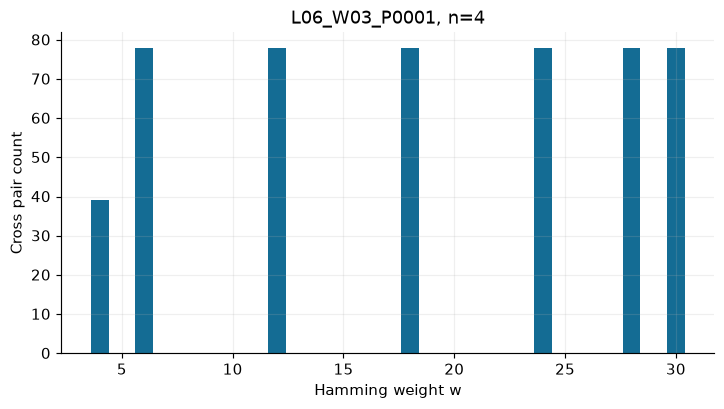

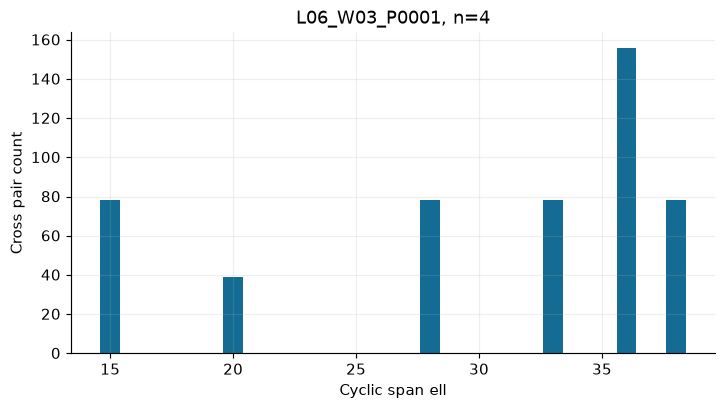

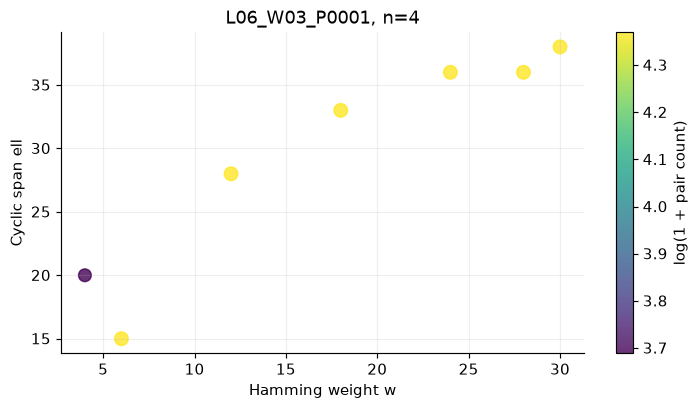

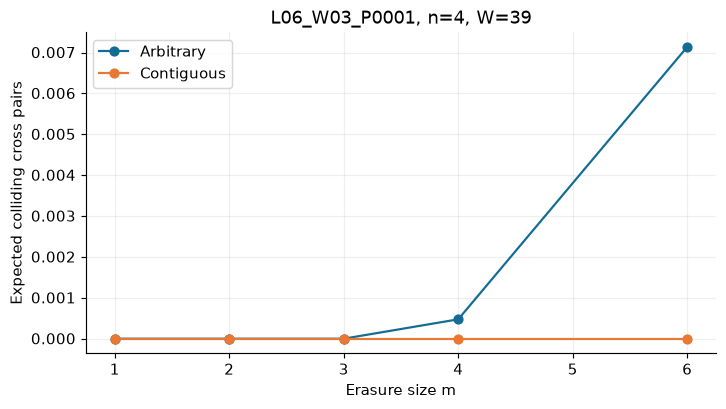

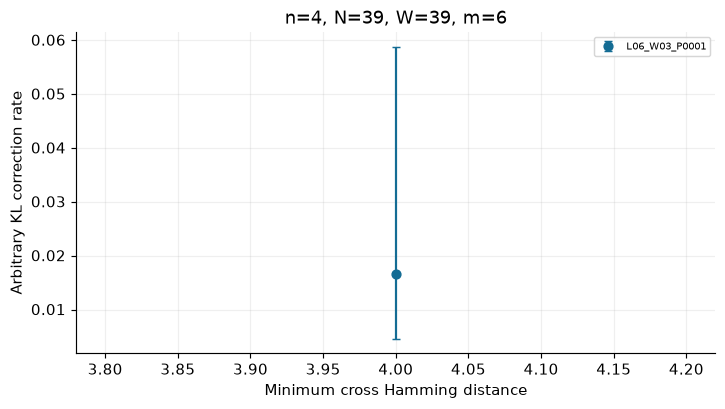

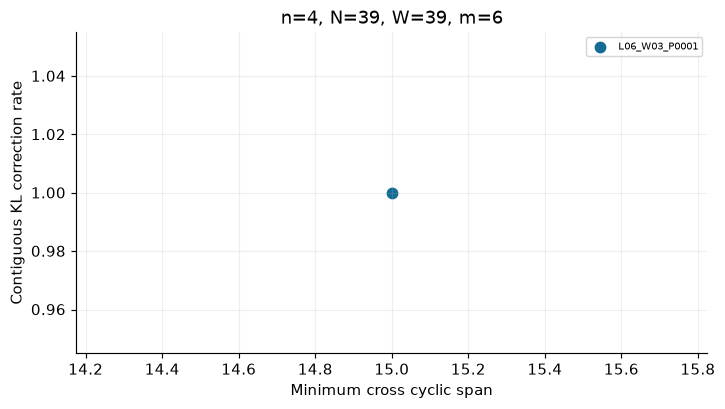

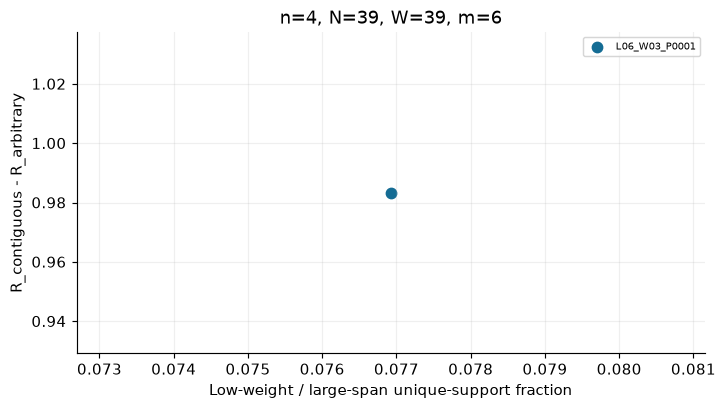

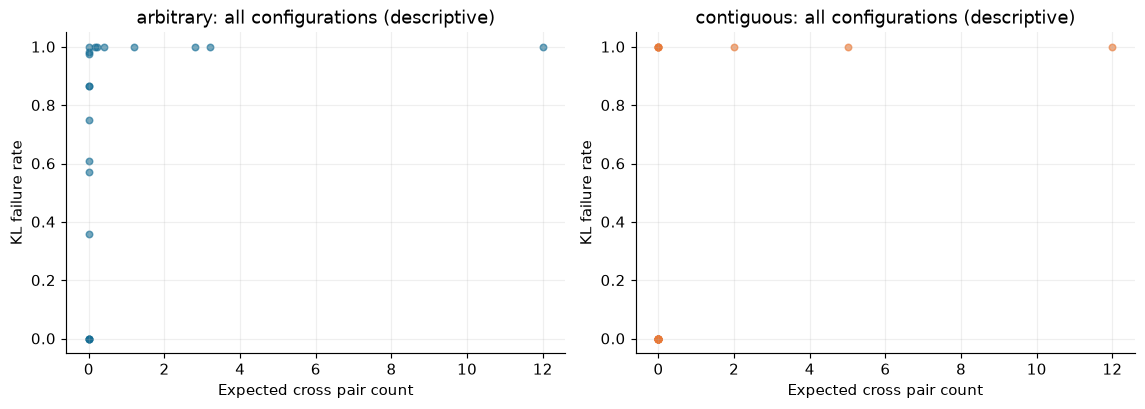

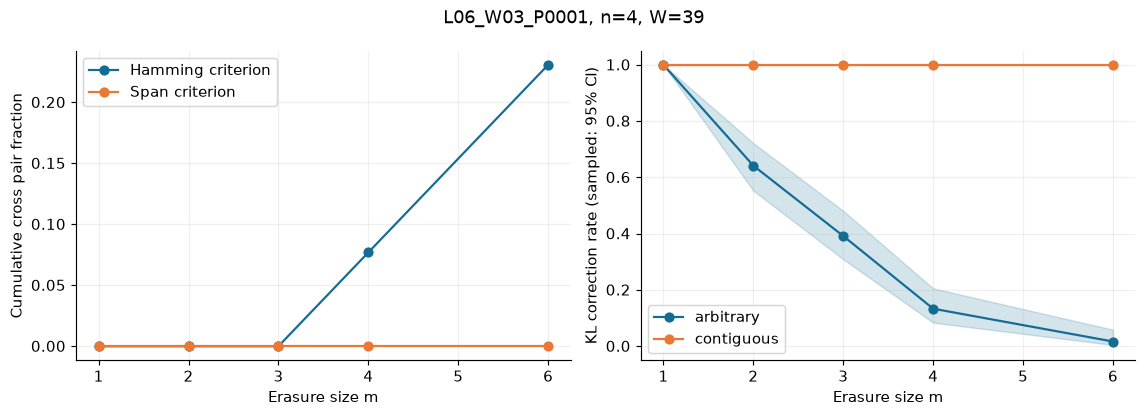

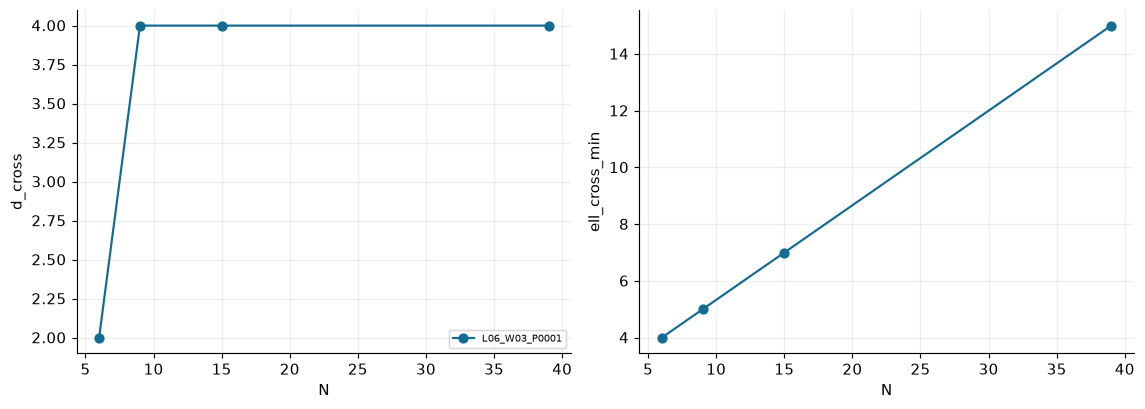

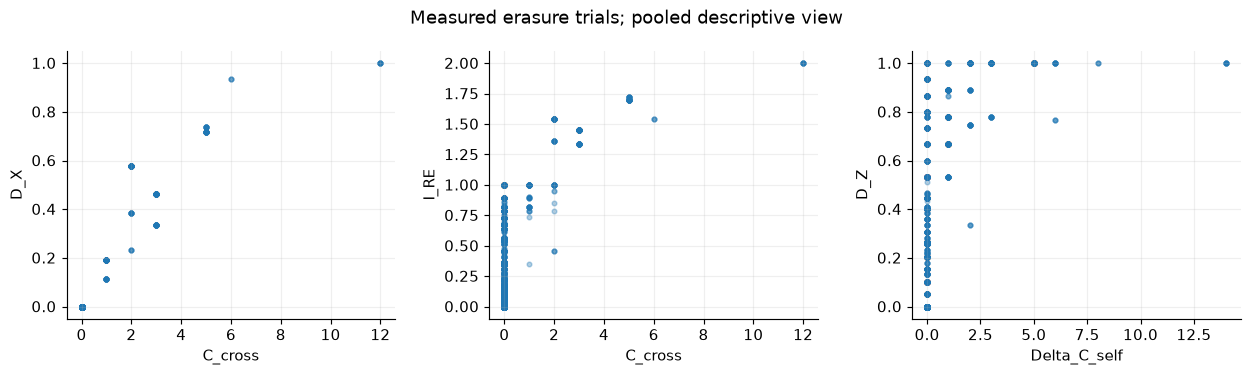

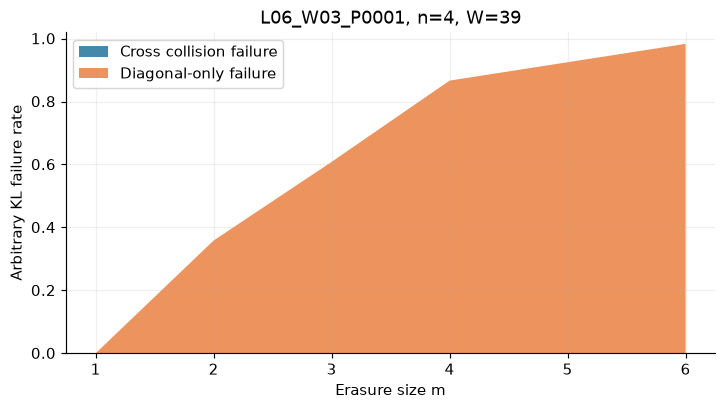

,table,rows,columns
0,logical_summary,4,31
1,spectra,164,19
2,joint_spectrum,51,19
3,unique_supports,1596,22
4,dangerous_supports,66,22
5,expected_collisions,20,30
6,erasure_collisions,1740,40
7,orbit_pairs,1610,22
8,collision_profiles,0,0
9,low_weight_large_span_supports,87,22


In [12]:
if RESULTS is not None:
    FIGURES=make_figures(RESULTS,CONFIG)
    for fig in FIGURES:
        display(fig)
    print("DataFrames:")
    display(pd.DataFrame([{"table":k,"rows":len(v),"columns":len(v.columns)} for k,v in RESULTS.items() if isinstance(v,pd.DataFrame)]))


## 24. 結果まとめ・仮説の判定・次の設計

small weight / large spanは**固定cross pairのcollision機構**として厳密に意味を持ちます。
それが観測された訂正率差の主原因かは、実際のcross発生率と対角だけのKL失敗率を調べて判断します。
両訂正率が一定の場合やpair数不足では「無相関」とは結論しません。

設計候補はd_crossの増大、低weight supportの減少、collision期待数の低減、ell_cross_minの維持です。
同じDのmultiplicityを減らすと期待組数は減りますが、collision発生確率が必ず減るわけではありません。
最終的な設計評価には対角KL一致と、同じdomain/mでの完全なKL訂正率を併用します。

理論背景: [Li & Boyle, Appendix E](https://arxiv.org/html/2311.13040v2#A5)、
[Knill & Laflamme, Theory of quantum error-correcting codes](https://doi.org/10.1103/PhysRevA.55.900)。
今回のseed条件・recoverability・漏洩量の運用上の定義は同梱の既存研究provenanceに従います。


In [13]:
if RESULTS is not None:
    final_text=conclusions(RESULTS)
    display(Markdown(final_text))
    display(RESULTS["summary"])
    display(RESULTS["spectra"][RESULTS["spectra"].metric_type.isin(["cross_hamming","cross_span"])])
    display(RESULTS["dangerous_supports"])
    display(RESULTS["comparison"][["pair_id","inflation_n","N","erasure_size","expected_cross_collision_arbitrary","expected_cross_collision_contiguous","R_KL_arbitrary","R_KL_contiguous"]])
    display(RESULTS["correlations"])
    if SAVE_RESULTS: (Path(OUTPUT_DIR)/"conclusions.md").write_text(final_text,encoding="utf-8")
else:
    print("本番の結果は未計算です。準備表と実行済み小規模例を確認してください。")


# Collision解析の観測結果

解析したlogical pairは1組、pair×inflationは4条件です。

設定した閾値によるAタイプ（連続に強く任意に弱い）は4条件です。

情報漏洩I_REの計算済み試行は1740件です。未計算値は欠測です。

cross collision と KL off-diagonal failure の一致を全試行で確認しました。KL failure rate = P(cross collision) + P(diagonal failure かつ crossなし) を確認しました。

期待collision数はpair数の期待値です。collision発生確率やKL failure rateとは異なります。

相関は同じn,N,window,mの異なるpair間のみです。3pair未満・定数変数は係数を欠測にします。係数は探索的で、未知pairへの予測精度を示しません。

全巡回orbitの状態は並進不変なので、full_ringの固定m連続消失KL訂正率は0または1です。

設計候補はd_cross増大、低weight supportの削減、期待cross collision数の低減、ell_cross_min維持です。ただしdiagonal条件の評価を必ず併用します。

n=0は検証用です。原論文のinflation後の保証を適用しません。

Aタイプの存在とlow-weight/large-span supportを比較できますが、機構がKL failure全体を説明するかはdiagonal-only failure率も確認してください。


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,...,number_cross_pairs,number_unique_cross_supports,low_weight_max,large_span_min,low_weight_large_span_pair_fraction,low_weight_large_span_unique_fraction,low_weight_pair_fraction,d_self_0,ell_self_0_min,d_self_1,ell_self_1_min,geometry_seconds
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,...,12,6,4,3,1.000000,1.000000,1.000000,2,4,6,6,0.000084
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,...,27,27,4,5,1.000000,1.000000,1.000000,2,4,6,8,0.000213
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,...,75,75,4,8,0.200000,0.200000,0.200000,6,6,6,12,0.000320
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,...,507,507,4,20,0.076923,0.076923,0.076923,6,12,6,28,0.002442


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,metric_type,value,count,fraction,cumulative_count,cumulative_fraction
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming,2,6,0.500000,6,0.500000
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_hamming,4,6,0.500000,12,1.000000
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_span,4,6,0.500000,6,0.500000
5,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross_span,5,6,0.500000,12,1.000000
24,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross_hamming,4,27,1.000000,27,1.000000
26,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross_span,5,18,0.666667,18,0.666667
27,6,3,3,True,True,True,L06_W03_P0001,000111,010101,1,9,9,3,cross_span,6,9,0.333333,27,1.000000
46,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,5,cross_hamming,4,15,0.200000,15,0.200000
47,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,5,cross_hamming,6,30,0.400000,45,0.600000
48,6,3,3,True,True,True,L06_W03_P0001,000111,010101,2,15,15,5,cross_hamming,10,30,0.400000,75,1.000000


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,orbit_size_1,pair_type,support_mask,difference_positions,hamming_weight,cyclic_span,multiplicity,support_multiplicity,shift_index_a,shift_index_b
0,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x12,"[1, 4]",2,4,2,2,0,0
1,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x24,"[0, 3]",2,4,2,2,1,1
2,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x9,"[2, 5]",2,4,2,2,2,0
3,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x2d,"[0, 2, 3, 5]",4,5,2,2,0,1
4,6,3,3,True,True,True,L06_W03_P0001,000111,010101,0,6,6,2,cross,0x1b,"[1, 2, 4, 5]",4,5,2,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x180000c00,"[6, 7, 27, 28]",4,20,1,1,15,10
62,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x300001800,"[5, 6, 26, 27]",4,20,1,1,16,11
63,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0x600003000,"[4, 5, 25, 26]",4,20,1,1,17,12
64,6,3,3,True,True,True,L06_W03_P0001,000111,010101,4,39,39,13,cross,0xc00006000,"[3, 4, 24, 25]",4,20,1,1,18,0


,pair_id,inflation_n,N,erasure_size,expected_cross_collision_arbitrary,expected_cross_collision_contiguous,R_KL_arbitrary,R_KL_contiguous
0,L06_W03_P0001,0,6,1,0.000000,0.0,1.000000,1.0
1,L06_W03_P0001,0,6,2,0.400000,0.0,0.000000,0.0
2,L06_W03_P0001,0,6,3,1.200000,0.0,0.000000,0.0
3,L06_W03_P0001,0,6,4,2.800000,2.0,0.000000,0.0
4,L06_W03_P0001,0,6,6,12.000000,12.0,0.000000,0.0
5,L06_W03_P0001,1,9,1,0.000000,0.0,1.000000,1.0
6,L06_W03_P0001,1,9,2,0.000000,0.0,0.250000,1.0
7,L06_W03_P0001,1,9,3,0.000000,0.0,0.000000,0.0
8,L06_W03_P0001,1,9,4,0.214286,0.0,0.000000,0.0
9,L06_W03_P0001,1,9,6,3.214286,5.0,0.000000,0.0


,inflation_n,N,domain_mode,window_size,erasure_size,x,y,n,pearson,spearman,status,note,Pearson,Spearman
0,0,6,full_ring,6,1,d_cross,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
1,0,6,full_ring,6,1,ell_cross_min,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
2,0,6,full_ring,6,1,expected_cross_collision_arbitrary,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
3,0,6,full_ring,6,1,expected_cross_collision_contiguous,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
4,0,6,full_ring,6,1,low_weight_large_span_unique_fraction,correction_rate_gap,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,4,39,full_ring,39,6,d_cross,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
96,4,39,full_ring,39,6,ell_cross_min,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
97,4,39,full_ring,39,6,expected_cross_collision_arbitrary,R_KL_arbitrary,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN
98,4,39,full_ring,39,6,expected_cross_collision_contiguous,R_KL_contiguous,1,NaN,NaN,fewer_than_3_pairs,No causal or out-of-sample prediction claim; s...,NaN,NaN


## 補足実行: 同じ組成の7 logical pairsでの比較

既存seed catalogの長さ8・k0=k1=4の最初の7pairを使用します。
n=0,1,2、m=1,2,3,4,6、exact上限200、sampled各120draw。n=0は検証用です。
これは少数pairでの探索的な比較で、得られた相関を学習済み予測モデルや一般則とは扱いません。
詳細結果は `example_multi_pair/` に保存します。


,seed_length,k0,k1,adjacent_swap_valid,paper_no_self_swap_0,paper_no_self_swap_1,pair_id,seed_0,seed_1,inflation_n,N,orbit_size_0,...,number_cross_pairs,number_unique_cross_supports,low_weight_max,large_span_min,low_weight_large_span_pair_fraction,low_weight_large_span_unique_fraction,low_weight_pair_fraction,d_self_0,ell_self_0_min,d_self_1,ell_self_1_min,geometry_seconds
0,8,4,4,True,True,True,L08_W04_P0001,00001111,00011011,0,8,8,...,64,32,4,4,0.500000,0.500000,0.750000,2,5,4,4,0.000182
1,8,4,4,True,True,True,L08_W04_P0001,00001111,00011011,1,12,12,...,144,96,4,6,0.333333,0.375000,0.500000,2,5,2,5,0.000317
2,8,4,4,True,True,True,L08_W04_P0001,00001111,00011011,2,20,20,...,400,360,4,10,0.000000,0.000000,0.100000,6,8,6,7,0.000796
3,8,4,4,True,True,True,L08_W04_P0002,00001111,00100111,0,8,8,...,64,32,4,4,0.500000,0.500000,0.750000,2,5,4,4,0.000159
4,8,4,4,True,True,True,L08_W04_P0002,00001111,00100111,1,12,12,...,144,102,4,6,0.333333,0.176471,0.500000,2,5,2,5,0.000308
5,8,4,4,True,True,True,L08_W04_P0002,00001111,00100111,2,20,20,...,400,360,4,10,0.000000,0.000000,0.100000,6,8,6,7,0.000792
6,8,4,4,True,True,True,L08_W04_P0003,00001111,00101011,0,8,8,...,64,48,4,4,0.875000,0.833333,0.875000,2,5,4,4,0.000160
7,8,4,4,True,True,True,L08_W04_P0003,00001111,00101011,1,12,12,...,144,144,4,6,0.333333,0.333333,0.416667,2,5,4,5,0.000305
8,8,4,4,True,True,True,L08_W04_P0003,00001111,00101011,2,20,20,...,400,400,4,10,0.000000,0.000000,0.000000,6,8,4,7,0.000771
9,8,4,4,True,True,True,L08_W04_P0004,00001111,00101101,0,8,8,...,64,14,4,4,0.750000,0.714286,0.750000,2,5,2,5,0.000157


,inflation_n,N,domain_mode,window_size,erasure_size,x,y,n,pearson,spearman,status,note,Pearson,Spearman
0,0,8,full_ring,8,1,d_cross,R_KL_arbitrary,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
1,0,8,full_ring,8,1,ell_cross_min,R_KL_contiguous,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
2,0,8,full_ring,8,1,expected_cross_collision_arbitrary,R_KL_arbitrary,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
3,0,8,full_ring,8,1,expected_cross_collision_contiguous,R_KL_contiguous,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
4,0,8,full_ring,8,1,low_weight_large_span_unique_fraction,correction_rate_gap,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,2,20,full_ring,20,6,d_cross,R_KL_arbitrary,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
71,2,20,full_ring,20,6,ell_cross_min,R_KL_contiguous,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
72,2,20,full_ring,20,6,expected_cross_collision_arbitrary,R_KL_arbitrary,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN
73,2,20,full_ring,20,6,expected_cross_collision_contiguous,R_KL_contiguous,7,NaN,NaN,constant_variable,No causal or out-of-sample prediction claim; s...,NaN,NaN


# Collision解析の観測結果

解析したlogical pairは7組、pair×inflationは21条件です。

設定した閾値によるAタイプ（連続に強く任意に弱い）は15条件です。

情報漏洩I_REの計算済み試行は0件です。未計算値は欠測です。

cross collision と KL off-diagonal failure の一致を全試行で確認しました。KL failure rate = P(cross collision) + P(diagonal failure かつ crossなし) を確認しました。

期待collision数はpair数の期待値です。collision発生確率やKL failure rateとは異なります。

相関は同じn,N,window,mの異なるpair間のみです。3pair未満・定数変数は係数を欠測にします。係数は探索的で、未知pairへの予測精度を示しません。

全巡回orbitの状態は並進不変なので、full_ringの固定m連続消失KL訂正率は0または1です。

設計候補はd_cross増大、低weight supportの削減、期待cross collision数の低減、ell_cross_min維持です。ただしdiagonal条件の評価を必ず併用します。

n=0は検証用です。原論文のinflation後の保証を適用しません。

Aタイプの存在とlow-weight/large-span supportを比較できますが、機構がKL failure全体を説明するかはdiagonal-only failure率も確認してください。


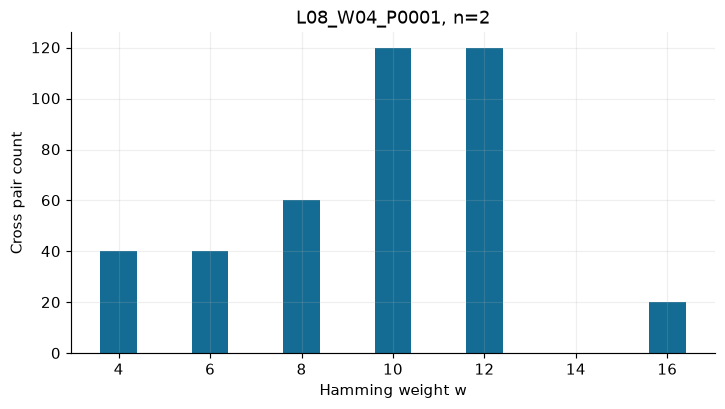

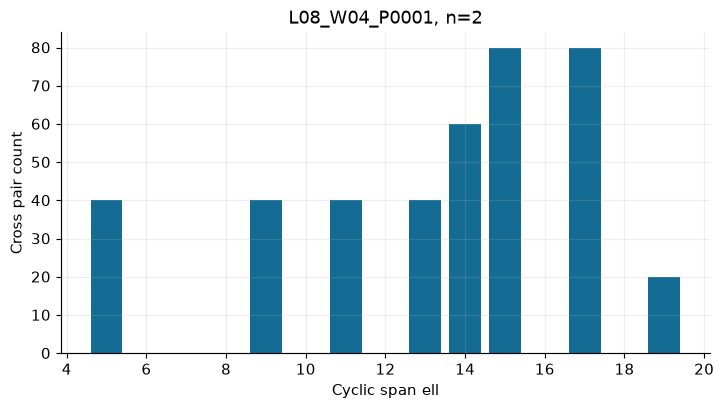

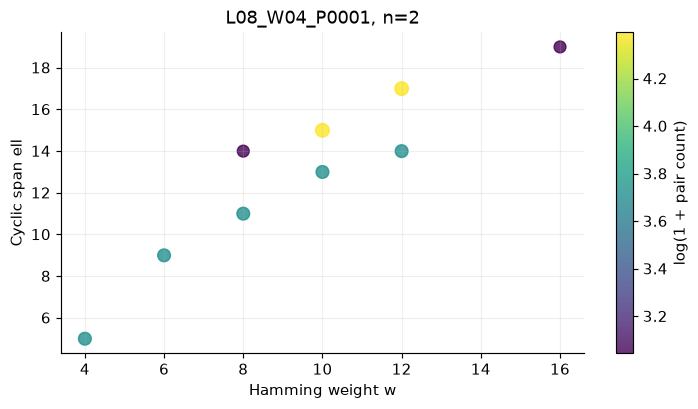

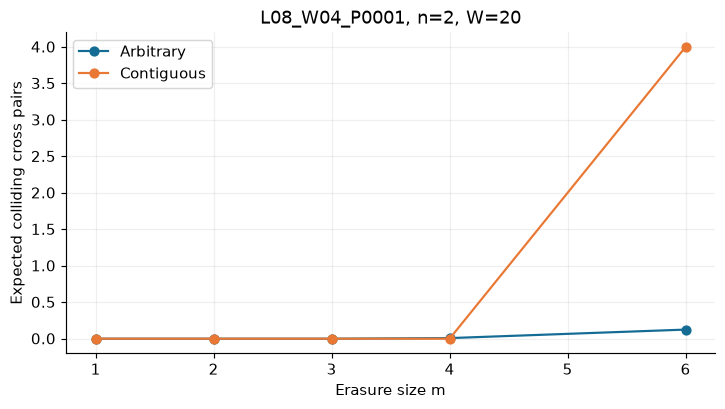

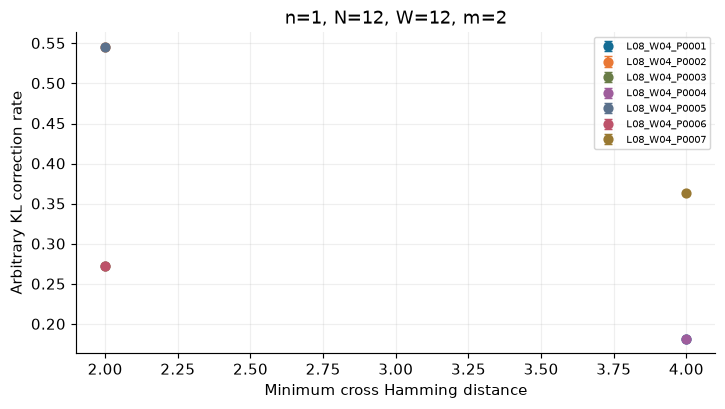

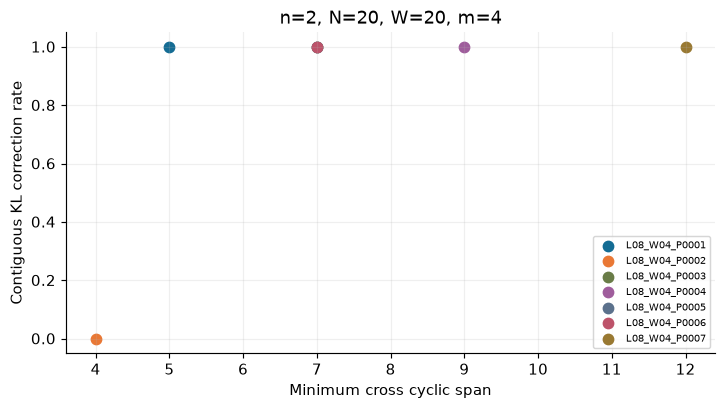

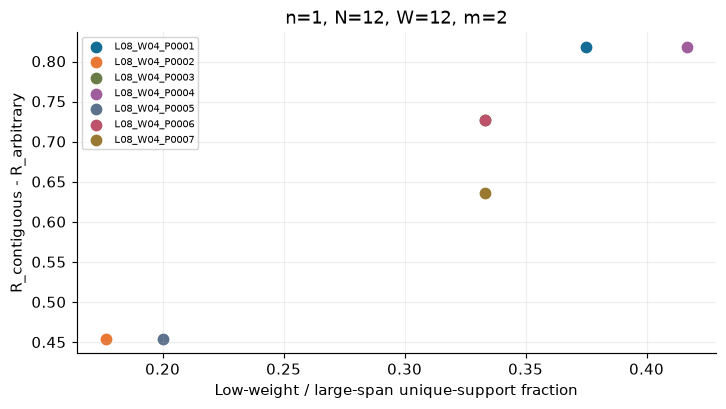

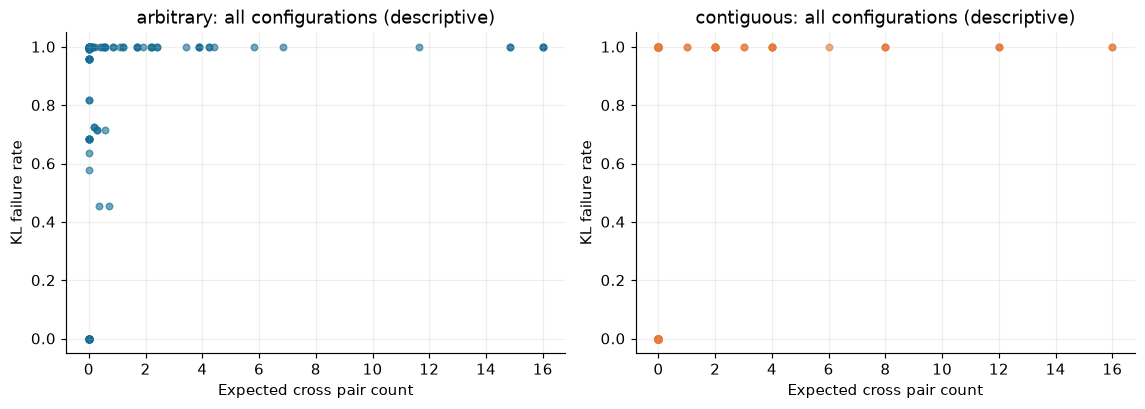

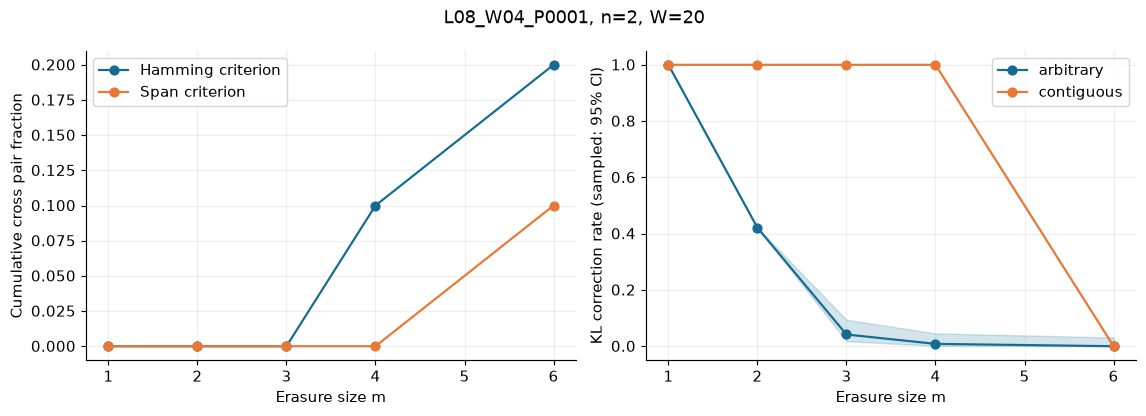

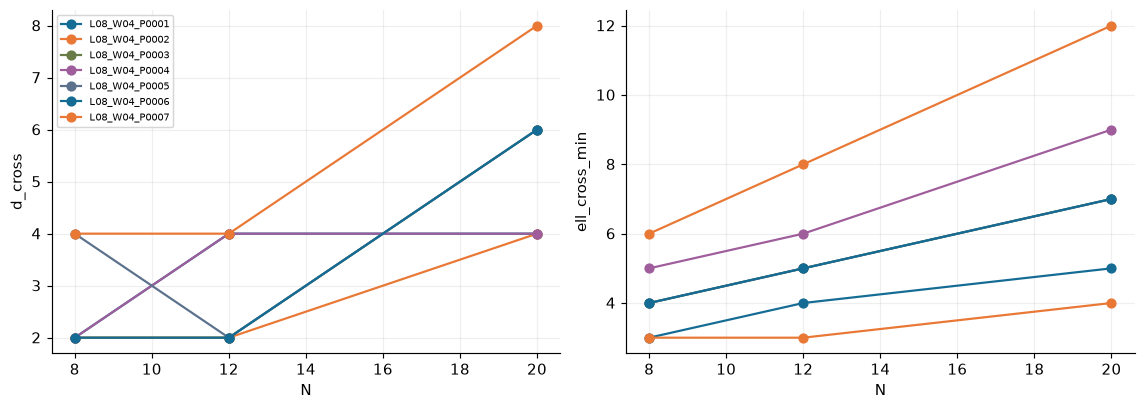

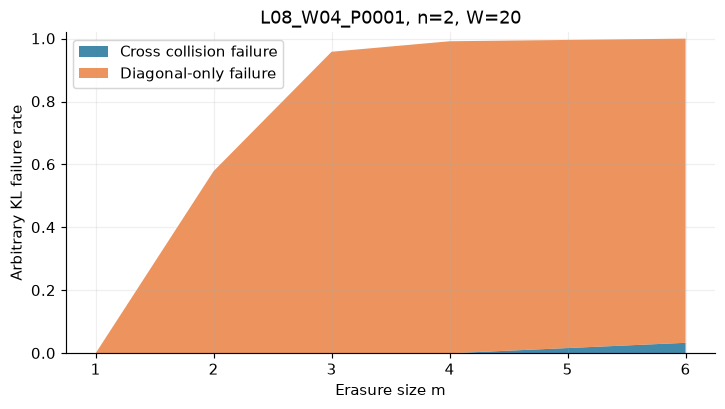

In [14]:
MULTI_CONFIG=dict(CONFIG)
MULTI_CONFIG.update(LOGICAL_PAIRS=[
    dict(pair_id=f"L08_W04_P{i:04d}",seed_0="00001111",seed_1=b)
    for i,b in enumerate(["00011011","00100111","00101011","00101101","00110011","00110101","01010101"],start=1)
], INFLATION_LIST=[0,1,2],COMPUTE_LEAKAGE=False,STORE_PAIR_DETAILS=False,
OUTPUT_DIR="example_multi_pair",MAX_PLOT_GROUPS=2)
MULTI=run_analysis(MULTI_CONFIG,progress=lambda message: None)
display(MULTI["summary"])
display(MULTI["correlations"])
display(Markdown(conclusions(MULTI)))
multi_figures=make_figures(MULTI,MULTI_CONFIG)
for fig in multi_figures: display(fig)
if SAVE_RESULTS:
    (Path(MULTI_CONFIG["OUTPUT_DIR"])/"conclusions.md").write_text(conclusions(MULTI),encoding="utf-8")


## 補足実行: 固定windowでの検証

元の1pairでn=1,2、W=6,12、m=2,4,6を比較します。W>Nはskipとして記録します。
window内の一様m-subsetの期待値と、window内の連続消失区間に対する期待値を区別します。


In [15]:
WINDOW_CONFIG=dict(CONFIG)
WINDOW_CONFIG.update(INFLATION_LIST=[1,2],ERASURE_DOMAIN_MODE="window",WINDOW_SIZE_LIST=[6,12],
ERASURE_SIZE_LIST=[2,4,6],OUTPUT_DIR="example_window",STORE_PAIR_DETAILS=False,SAVE_FIGURES=False,
SAVE_COLLISION_PROFILES=True)
WINDOW=run_analysis(WINDOW_CONFIG,progress=lambda message: None)
display(WINDOW["comparison"][["pair_id","N","window_size","erasure_size","expected_cross_collision_arbitrary","expected_cross_collision_contiguous","expected_cross_collision_contiguous_full_ring","R_KL_arbitrary","R_KL_contiguous"]])
display(WINDOW["skipped"])


,pair_id,N,window_size,erasure_size,expected_cross_collision_arbitrary,expected_cross_collision_contiguous,expected_cross_collision_contiguous_full_ring,R_KL_arbitrary,R_KL_contiguous
0,L06_W03_P0001,9,6,2,0.000000,0.0,0,0.333333,1.0
1,L06_W03_P0001,9,6,4,0.333333,0.0,0,0.000000,0.0
2,L06_W03_P0001,9,6,6,5.000000,5.0,5,0.000000,0.0
3,L06_W03_P0001,15,6,2,0.000000,0.0,0,0.800000,1.0
4,L06_W03_P0001,15,6,4,0.000000,0.0,0,0.200000,1.0
5,L06_W03_P0001,15,6,6,0.000000,0.0,0,0.000000,0.0
6,L06_W03_P0001,15,12,2,0.000000,0.0,0,0.454545,1.0
7,L06_W03_P0001,15,12,4,0.014141,0.0,0,0.025000,1.0
8,L06_W03_P0001,15,12,6,0.225108,0.0,0,0.000000,0.0


,pair_id,seed_0,seed_1,inflation_n,N,domain_mode,window_size,erasure_size,erasure_type,calculation_mode,population_patterns,planned_trials,status,reason
6,L06_W03_P0001,000111,010101,1,9,window,12,2,arbitrary,exact,0,0,skipped,window_size>N
7,L06_W03_P0001,000111,010101,1,9,window,12,2,contiguous,exact,11,0,skipped,window_size>N
8,L06_W03_P0001,000111,010101,1,9,window,12,4,arbitrary,exact,0,0,skipped,window_size>N
9,L06_W03_P0001,000111,010101,1,9,window,12,4,contiguous,exact,9,0,skipped,window_size>N
10,L06_W03_P0001,000111,010101,1,9,window,12,6,arbitrary,exact,0,0,skipped,window_size>N
11,L06_W03_P0001,000111,010101,1,9,window,12,6,contiguous,exact,7,0,skipped,window_size>N
